## Computational Homework 2, 2026


- Name: Oscar Flores Gaitán
- Course: PHYS620: Classical Mechanics II


---



#### Due September 23


#### Including friction in Lagrangian mechanics

1. Assume a single particle moving in one dimension is subjected to a net **conservative** force
   $$F = -\frac{\partial U}{\partial x}$$
   and a friction force $F_{\rm fric}$. Define the Lagrangian as
   $$\mathcal{L} = \mathcal{T} - U$$
   and show that the appropriate modification to the Euler-Lagrange equation is
   $$\frac{\partial \mathcal{L}}{\partial x} + F_{\rm fric} = \frac{d}{dt} \frac{\partial \mathcal{L}}{\partial \dot{x}}.$$
   
---

### Derivation of the Modified Euler-Lagrange Equation with Friction

Newton's second law:
$$m \ddot{x} = F_{\rm c} + F_{\rm fric} = -\frac{\partial U}{\partial x} + F_{\rm fric}$$

$$\mathcal{L} = \mathcal{T} - U = \frac{1}{2} m \dot{x}^2 - U(x)$$

$$\frac{\partial \mathcal{L}}{\partial x} = -\frac{\partial U}{\partial x}$$

$$\frac{\partial \mathcal{L}}{\partial \dot{x}} = m \dot{x} \implies \frac{d}{dt}\left(\frac{\partial \mathcal{L}}{\partial \dot{x}}\right) = m \ddot{x}$$


Substituting into the Euler-Lagrange equation:


$$ \frac{\partial \mathcal{L}}{\partial x} - \frac{d}{dt}\left(\frac{\partial \mathcal{L}}{\partial \dot{x}}\right)   + F_{\rm fric} = 0$$

$$\implies \frac{\partial \mathcal{L}}{\partial x} + F_{\rm fric} = \frac{d}{dt}\left(\frac{\partial \mathcal{L}}{\partial \dot{x}}\right)$$

#### Oscillations about an equilibrium point

1. Consider Example 7.6 in your textbook, the bead on the spinning wire. Equation 7.69 gives the equation of motion (EOM):

$$\ddot{\theta} = \left(\omega^2 \cos \theta - \frac{g}{R}\right) \sin \theta$$

While the EOM does not have an analytical solution, it can be solved numerically. The behavior of the system is determined by the ratio $\frac{\omega^2}{g/R}$.

2. Choose a value of $\frac{\omega^2}{g/R}$ that is much less than 1. Select a value of $R$ that is of order 1 meter. The exact number is up to you. Start the bead at a small displacement from the equilibrium position at the bottom of the hoop. The exact angle of your displacement is up to you. Use `sympy` to *numerically* solve your equation of motion to find $\theta(t)$ for 5 full rotations of the hoop. Plot your answer.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

plt.rcParams.update({'font.size':16, 'axes.labelsize':16})

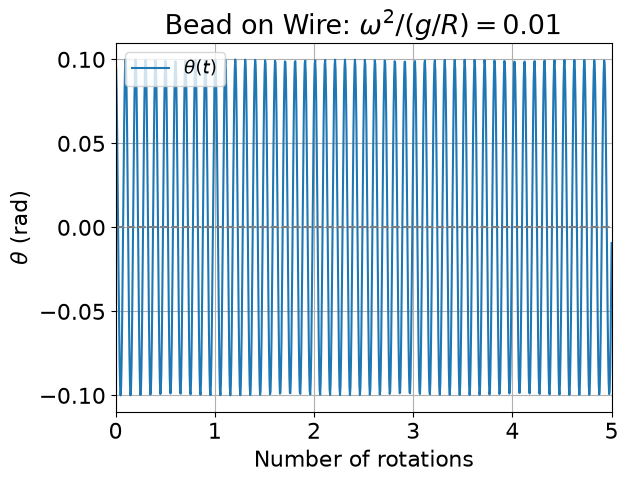

In [17]:
# Parameters
g = 9.8
R = 1.0
ratio = 0.01 # omega^2 / (g/R) << 1
omega = np.sqrt(ratio * g / R)
theta0 = 0.1 # initial angle in radians

# Equation of motion: theta'' = (omega^2 * cos(theta) - g/R) * sin(theta)
th = sp.Symbol('th')
f = (omega**2 * sp.cos(th) - g / R) * sp.sin(th)
f_num = sp.lambdify(th, f)

# Integrate for 5 rotations
T = 2 * np.pi / omega
t_eval = np.linspace(0, 5 * T, 1000)
sol = solve_ivp(lambda t, y: [y[1], f_num(y[0])], (0, 5 * T), [theta0, 0], t_eval=t_eval)

plt.plot(sol.t / T, sol.y[0], label=r'$\theta(t)$')
plt.axhline(0, color='gray', linestyle='--')
plt.xlim(0, 5)
plt.xlabel('Number of rotations')
plt.ylabel(r'$\theta$ (rad)')
plt.title(r'Bead on Wire: $\omega^2 / (g/R) = 0.01$')
plt.legend(loc='upper left', fontsize='small')
plt.grid(True)
plt.show()

3. Now pick a value of $\frac{\omega^2}{g/R}$ that is comfortably higher than 1. Again, start the bead at a small displacement from the bottom of the hoop. Use `sympy` to numerically find $\theta(t)$ for five rotations of the hoop and plot your answer. In a Markdown cell, explain how your answer differs from question 2.

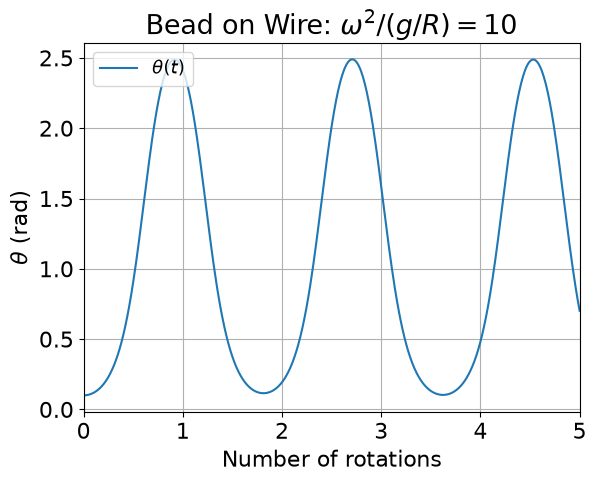

In [18]:
# Parameters
ratio = 10  # > 1
omega = np.sqrt(ratio * g / R)
theta0 = 0.1

# Equation of motion
f = (omega**2 * sp.cos(th) - g / R) * sp.sin(th)
f_num = sp.lambdify(th, f)

# Integrate for 5 rotations
T = 2 * np.pi / omega
t_eval = np.linspace(0, 5 * T, 500)
sol = solve_ivp(lambda t, y: [y[1], f_num(y[0])], (0, 5 * T), [theta0, 0], t_eval=t_eval)

plt.plot(sol.t / T, sol.y[0], label=r'$\theta(t)$')
plt.xlim(0, 5)
plt.xlabel('Number of rotations')
plt.ylabel(r'$\theta$ (rad)')
plt.title(r'Bead on Wire: $\omega^2 / (g/R) = 10$')
plt.legend(loc='upper left', fontsize='small')
plt.grid(True)
plt.show()

In [10]:
print(f"Equilibrium theta_0 = {np.arccos(1 / ratio):.1f}")

Equilibrium theta_0 = 1.5


In question 2 (where $\frac{\omega^2}{g/R} = 0.01$), the position $\theta = 0$ is in stable equilibrium whereas in question 3 (where $\frac{\omega^2}{g/R} = 10$), $\theta = 0$ is in unstable equilibrium. The bead is pushed away and oscillates around a new stable equilibrium at $\theta_0 \approx 1.5\text{ rad}$.


#### Testing `sympy.calculus.euler.euler_equations`

In Figure 7.12 of your textbook, a yoyo is represented by a cylinder of radius $R$ rolling down a string with negligible mass at angular speed $\omega$.

4. Write the Lagrangian for one generalized coordinate, the vertical distance of the string-cylinder contact point from the yoyo-er's hand, and try to use `sympy.calculus.euler.euler_equations` to find the Euler-Lagrange equation.

In [7]:
import sympy as sp
from sympy.calculus.euler import euler_equations

# Parameters and symbols
t = sp.Symbol('t')
m, g, R = sp.symbols('m g R', positive=True)
y = sp.Function('y')(t)
ydot = y.diff(t)

# T = 1/2  m ydot^2 + 1/2 I omega^2 = 3/4 m ydot^2
# U = -mgy
# And we know that L = T - U
L = sp.Rational(3, 4) * m * ydot**2 + m * g * y

# Euler-Lagrange equation
EL = euler_equations(L, [y])[0]
acc = sp.solve(EL, y.diff(t, 2))[0]

print("Lagrangian:", L)
print("Euler-Lagrange Equation:", EL)
print("Acceleration y'':", acc)

Lagrangian: g*m*y(t) + 3*m*Derivative(y(t), t)**2/4
Euler-Lagrange Equation: Eq(g*m - 3*m*Derivative(y(t), (t, 2))/2, 0)
Acceleration y'': 2*g/3


5. Derive the Euler-Lagrange equation by hand. Does your solution match `sympy`'s solution? If `sympy` was unsuccessful at solving the Euler-Lagrange equation, how might you improve your calculation? Remember that, like any physicist, a computer algebra system likes to be fed information in the simplest form possible.
---

Let $\omega R = \dot{y}$ $\implies \omega = \dot{y}/R$, and $I = \frac{1}{2}mR^2$:
$$\mathcal{L} = \mathcal{T} - U = \frac{3}{4} m \dot{y}^2 + m g y$$
$$\frac{\partial \mathcal{L}}{\partial y} = m g, \qquad \frac{\partial \mathcal{L}}{\partial \dot{y}} = \frac{3}{2}m \dot{y}  \qquad \implies \frac{d}{dt}\left(\frac{\partial \mathcal{L}}{\partial \dot{y}}\right) = \frac{3}{2} m \ddot{y}$$
$$\frac{\partial \mathcal{L}}{\partial y} - \frac{d}{dt}\left(\frac{\partial \mathcal{L}}{\partial \dot{y}}\right) = 0 \implies m g - \frac{3}{2} m \ddot{y} = 0 \implies \ddot{y} = \frac{2}{3} g$$
---

Both calculations match each other. If SymPy struggled to solve the equation, I would simplify the system by hand before writing the Lagrangian. I would try reducing the problem to a single generalized coordinate (when possible) to eliminate redundant variables and evaluate the derivatives directly.